In [1]:
!pip install stim pymatching sinter numpy matplotlib

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.3/5.3 MB 39.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 625.9/625.9 kB 28.7 MB/s  0:00:00
  Created wheel for sinter: filename=sinter-1.16.0-py3-none-any.whl size=197605 sha256=9a73966cc03dd678f36dfc5ca961b8da1a1bbc7722db6160c666ed53042b9e86
  Stored in directory: /root/.cache/pip/wheels/21/d7/ee/20c9d539daa5f139b411ebf82465352547c07694101973ae3f
Successfully built sinter
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [pymatching]


In [3]:
import stim
circuit = stim.Circuit.generated(
    "repetition_code:memory",
    distance=3,
    rounds=9,
    before_round_data_depolarization=0.05,
)
print(circuit)


R 0 1 2 3 4
TICK
DEPOLARIZE1(0.05) 0 2 4
CX 0 1 2 3
TICK
CX 2 1 4 3
TICK
MR 1 3
DETECTOR(1, 0) rec[-2]
DETECTOR(3, 0) rec[-1]
REPEAT 8 {
    TICK
    DEPOLARIZE1(0.05) 0 2 4
    CX 0 1 2 3
    TICK
    CX 2 1 4 3
    TICK
    MR 1 3
    SHIFT_COORDS(0, 1)
    DETECTOR(1, 0) rec[-2] rec[-4]
    DETECTOR(3, 0) rec[-1] rec[-3]
}
M 0 2 4
DETECTOR(1, 1) rec[-2] rec[-3] rec[-5]
DETECTOR(3, 1) rec[-1] rec[-2] rec[-4]
OBSERVABLE_INCLUDE(0) rec[-1]


In [6]:
import numpy as np
import pymatching

def logical_error_rate(distance, p, shots=100_000):
    circuit = stim.Circuit.generated(
    "repetition_code:memory",
    distance=distance,
    rounds=distance * 3,
    before_round_data_depolarization=p,
    before_measure_flip_probability=p,
    after_reset_flip_probability=p,
)
    dem = circuit.detector_error_model(decompose_errors=True)
    matching = pymatching.Matching.from_detector_error_model(dem)

    sampler = circuit.compile_detector_sampler()
    detections, observables = sampler.sample(shots, separate_observables=True)

    predictions = matching.decode_batch(detections)
    errors = np.sum(np.any(predictions != observables, axis=1))
    return errors / shots

print(logical_error_rate(distance=3, p=0.05))

0.11764


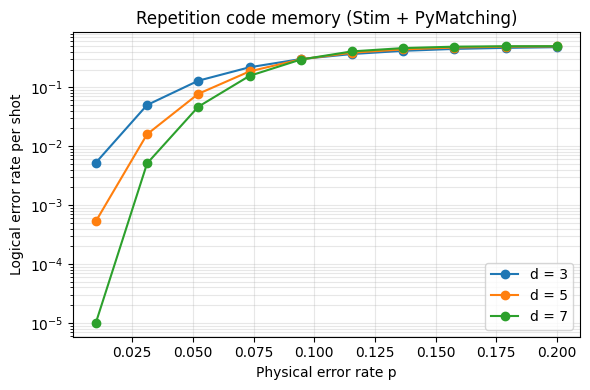

In [7]:
import matplotlib.pyplot as plt

distances = [3, 5, 7]
ps = np.linspace(0.01, 0.2, 10)

plt.figure(figsize=(6, 4))
for d in distances:
    rates = [logical_error_rate(d, p) for p in ps]
    plt.plot(ps, rates, marker="o", label=f"d = {d}")

plt.yscale("log")
plt.xlabel("Physical error rate p")
plt.ylabel("Logical error rate per shot")
plt.title("Repetition code memory (Stim + PyMatching)")
plt.legend()
plt.grid(True, which="both", alpha=0.3)
plt.tight_layout()
plt.savefig("repetition_code_threshold.png", dpi=200)
plt.show()